# E-commerce Analytics | Projeção de faturamento com regressão linear

Os dados são **100% sintéticos** e não representam operações ou clientes reais.

## Pergunta de negócio
> Qual faturamento bruto podemos esperar nos próximos seis meses, considerando tendência histórica, sazonalidade e diferentes planos de investimento em mídia?

**Etapas:** geração de dados sintéticos → validação de qualidade → análise exploratória → comparação de modelos → validação temporal → projeção sob cenários.

**Abordagem:** regressão linear simples e múltipla (`scikit-learn`), com reserva dos **12 meses mais recentes** para teste. Os cenários de mídia são **hipóteses de planejamento**, não previsões do investimento futuro.

## 1. Bibliotecas e carregamento da base

A granularidade dos dados é **mês × canal × categoria**. A receita é calculada a partir de pedidos × ticket médio.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PASTA_PROJETO = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ARQUIVO_BASE = PASTA_PROJETO / "dados" / "vendas_ecommerce_sinteticas.csv"
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
PASTA_RESULTADOS.mkdir(exist_ok=True)
assert ARQUIVO_BASE.exists(), f"Base não encontrada: {ARQUIVO_BASE}"

plt.rcParams.update({"figure.figsize": (12, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "figure.dpi": 110})
COR_AZUL, COR_TURQUESA, COR_LARANJA = "#153657", "#098F91", "#F59E48"

base = pd.read_csv(ARQUIVO_BASE, parse_dates=["mes_referencia"])
print(f"Registros: {len(base):,} | Períodos: {base['mes_referencia'].nunique()} | "+
      f"Período: {base['mes_referencia'].min():%m/%Y} a {base['mes_referencia'].max():%m/%Y}")
display(base.head(8))

Registros: 696 | Períodos: 58 | Período: 01/2022 a 10/2026


,mes_referencia,canal,categoria,sessoes,pedidos,ticket_medio_brl,receita_bruta_brl,investimento_marketing_brl
0,2022-01-01,Organico,Beleza,25131,625,159.08,99425.00,0.00
1,2022-01-01,Midia Paga,Beleza,17975,373,155.55,58020.15,15822.74
2,2022-01-01,CRM,Beleza,7501,293,151.30,44330.90,0.00
3,2022-01-01,Organico,Casa,22226,433,290.54,125803.82,0.00
4,2022-01-01,Midia Paga,Casa,16941,295,283.02,83490.90,12658.19
5,2022-01-01,CRM,Casa,6218,183,297.13,54374.79,0.00
6,2022-01-01,Organico,Moda,25616,561,201.09,112811.49,0.00
7,2022-01-01,Midia Paga,Moda,20567,408,202.54,82636.32,15295.31


## 2. Testes de integridade e dicionário das métricas

- `sessoes`: visitas ao e-commerce por canal/categoria.
- `pedidos`: pedidos confirmados na simulação.
- `ticket_medio_brl`: valor médio do pedido.
- `receita_bruta_brl`: pedidos × ticket médio; **não** desconta impostos, frete ou devoluções.
- `investimento_marketing_brl`: despesa fictícia atribuída exclusivamente ao canal *Mídia Paga*.

A taxa de conversão será calculada por **pedidos / sessões**, usando agregação ponderada (nunca média simples das taxas).

In [2]:
# Verificação explícita de qualidade antes da modelagem.
assert base.isna().sum().sum() == 0, "Existem valores ausentes."
assert not base.duplicated(["mes_referencia", "canal", "categoria"]).any(), "Há duplicatas."
assert (base["sessoes"] >= base["pedidos"]).all(), "Pedidos não podem exceder sessões."
assert (base[["sessoes", "pedidos", "receita_bruta_brl", "investimento_marketing_brl"]] >= 0).all().all()
assert np.allclose(base["receita_bruta_brl"], base["pedidos"] * base["ticket_medio_brl"], atol=0.011)
assert (base.loc[base["canal"] != "Midia Paga", "investimento_marketing_brl"] == 0).all()
assert base.groupby("mes_referencia").size().eq(12).all(), "Cada mês deveria ter 3 canais × 4 categorias."
print("Validação concluída: sem nulos, sem duplicidades e com consistência financeira.")

mensal = (base.groupby("mes_referencia", as_index=False)
          .agg(sessoes=("sessoes", "sum"), pedidos=("pedidos", "sum"),
               receita_bruta_brl=("receita_bruta_brl", "sum"),
               investimento_marketing_brl=("investimento_marketing_brl", "sum")))
mensal["taxa_conversao_pct"] = 100 * mensal["pedidos"] / mensal["sessoes"]
mensal["ticket_medio_ponderado_brl"] = mensal["receita_bruta_brl"] / mensal["pedidos"]
mensal["ano"] = mensal["mes_referencia"].dt.year
mensal["mes"] = mensal["mes_referencia"].dt.month
mensal["indice_tempo"] = np.arange(len(mensal), dtype=int)

display(mensal.tail(5))

Validação concluída: sem nulos, sem duplicidades e com consistência financeira.


,mes_referencia,sessoes,pedidos,receita_bruta_brl,investimento_marketing_brl,taxa_conversao_pct,ticket_medio_ponderado_brl,ano,mes,indice_tempo
53,2026-06-01,308521,7359,2070199.65,82925.59,2.385251,281.315349,2026,6,53
54,2026-07-01,317239,7513,2081365.88,84642.60,2.368246,277.035256,2026,7,54
55,2026-08-01,334265,8023,2258744.71,96781.53,2.400191,281.533679,2026,8,55
56,2026-09-01,326975,7775,2198959.83,73080.25,2.377858,282.824415,2026,9,56
57,2026-10-01,375448,9048,2597706.52,93512.47,2.409921,287.102843,2026,10,57


## 3. Análise exploratória (EDA)

Analisar tendência de faturamento, sazonalidade, mix de categorias e conversão por canal. **2026 é parcial** (janeiro–outubro), portanto não se deve comparar seu total anual aos anos completos sem ajuste.

Receita acumulada simulada: R$ 101,080,540.41
Conversão global ponderada: 2.32%


,categoria,receita_bruta_brl,participacao_pct
1,Casa,26841461.67,26.55
3,Moda,26477309.39,26.19
2,Eletronicos,24933437.75,24.67
0,Beleza,22828331.60,22.58


,canal,sessoes,pedidos,receita_bruta_brl,conversao_pct
0,CRM,2407600,85664,22451543.35,3.558066
2,Organico,8216821,179732,47226722.92,2.187367
1,Midia Paga,6048928,120599,31402274.14,1.993725


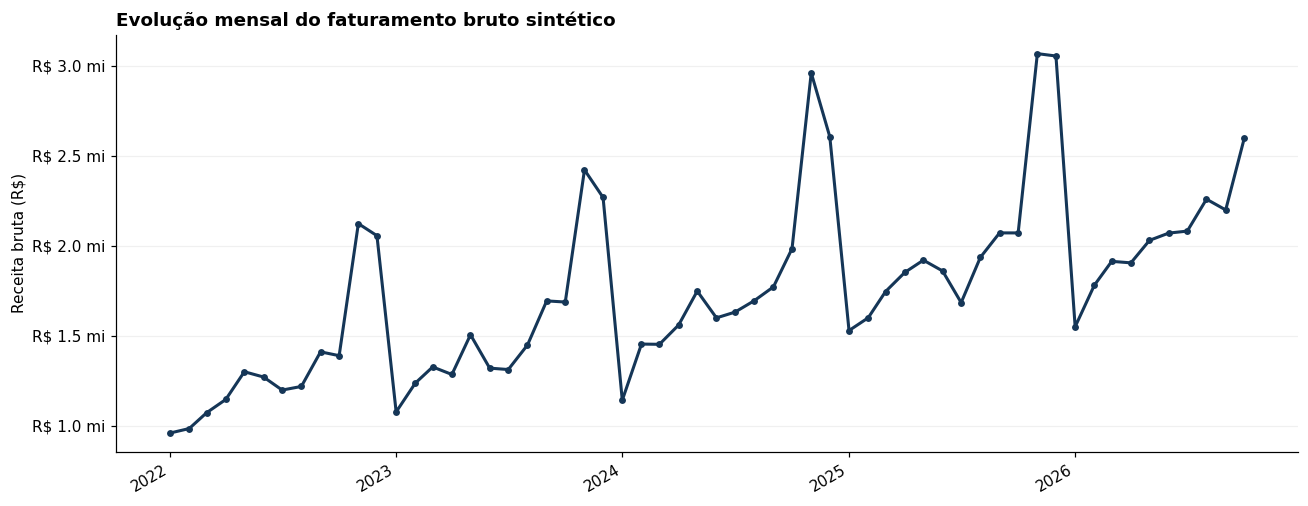

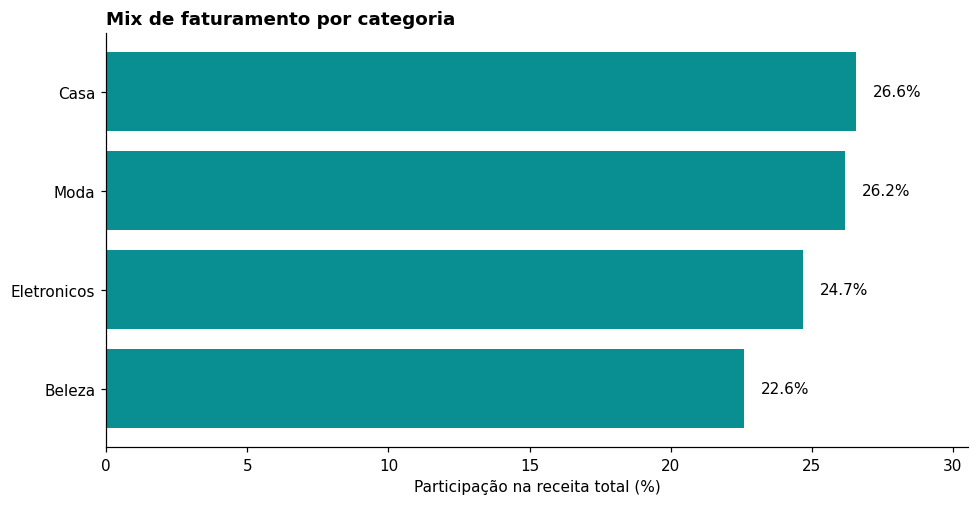

In [3]:
def abreviar_milhoes(valor, _):
    return f"R$ {valor/1_000_000:.1f} mi"

receita_total = base["receita_bruta_brl"].sum()
conversao_total = 100 * base["pedidos"].sum() / base["sessoes"].sum()
print(f"Receita acumulada simulada: R$ {receita_total:,.2f}")
print(f"Conversão global ponderada: {conversao_total:.2f}%")

mix_categoria = (base.groupby("categoria", as_index=False)["receita_bruta_brl"].sum()
                 .sort_values("receita_bruta_brl", ascending=False))
mix_categoria["participacao_pct"] = (100 * mix_categoria["receita_bruta_brl"] / receita_total).round(2)
por_canal = base.groupby("canal", as_index=False).agg(sessoes=("sessoes", "sum"),
                    pedidos=("pedidos", "sum"), receita_bruta_brl=("receita_bruta_brl", "sum"))
por_canal["conversao_pct"] = 100 * por_canal["pedidos"] / por_canal["sessoes"]
display(mix_categoria)
display(por_canal.sort_values("conversao_pct", ascending=False))

fig, ax = plt.subplots(figsize=(12, 4.7))
ax.plot(mensal["mes_referencia"], mensal["receita_bruta_brl"],
        color=COR_AZUL, marker="o", markersize=3.5, lw=2)
ax.set_title("Evolução mensal do faturamento bruto sintético", loc="left", weight="bold")
ax.set_ylabel("Receita bruta (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(abreviar_milhoes))
ax.grid(axis="y", alpha=.18)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "01_evolucao_receita.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.7))
ax.barh(mix_categoria["categoria"], mix_categoria["participacao_pct"], color=COR_TURQUESA)
ax.invert_yaxis()
ax.set_xlim(0, mix_categoria["participacao_pct"].max() * 1.15)
ax.set_xlabel("Participação na receita total (%)")
ax.set_title("Mix de faturamento por categoria", loc="left", weight="bold")
for i, val in enumerate(mix_categoria["participacao_pct"]):
    ax.text(val + .6, i, f"{val:.1f}%", va="center")
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "02_mix_categorias.png", dpi=180)
plt.show()

## 4. Modelagem preditiva: regressão linear

**Alvo:** faturamento bruto mensal (`receita_bruta_brl`).

**Modelos comparados:**

1. **Regressão linear simples:** usa apenas o índice temporal.
2. **Baseline sazonal:** prevê o mesmo faturamento do mês equivalente do ano anterior.
3. **Regressão linear múltipla:** usa índice temporal, investimento em mídia e mês do ano codificado com *one-hot encoding* (efeitos sazonais).

**Controle de vazamento (data leakage):** não usar pedidos, sessões, conversão ou ticket como preditores da receita, pois essas métricas não estão garantidas no momento da projeção. Investimento em mídia deve ser interpretado como orçamento conhecido ou planejado, não como futuro observado.

**Validação:** treino histórico até outubro de 2025; teste temporal de novembro de 2025 a outubro de 2026. Nada de embaralhamento aleatório.

In [4]:
TAMANHO_TESTE = 12
treino, teste = mensal.iloc[:-TAMANHO_TESTE].copy(), mensal.iloc[-TAMANHO_TESTE:].copy()
ALVO = "receita_bruta_brl"
COLUNAS = ["mes", "indice_tempo", "investimento_marketing_brl"]

regressao_simples = LinearRegression()
regressao_simples.fit(treino[["indice_tempo"]], treino[ALVO])
pred_simples = regressao_simples.predict(teste[["indice_tempo"]])

regressao_multipla = Pipeline(steps=[
    ("tratamento", ColumnTransformer(transformers=[
        ("mes_sazonal", OneHotEncoder(drop="first", handle_unknown="ignore"), ["mes"])
    ], remainder="passthrough")),
    ("modelo", LinearRegression())
])
regressao_multipla.fit(treino[COLUNAS], treino[ALVO])
pred_multipla = regressao_multipla.predict(teste[COLUNAS])

# Baseline sazonal: receita do mês correspondente do ano anterior.
baseline_12m = mensal[ALVO].shift(12).iloc[-TAMANHO_TESTE:].to_numpy()

def metricas(nome, real, previsto):
    return {"modelo": nome,
            "MAE (R$)": mean_absolute_error(real, previsto),
            "RMSE (R$)": np.sqrt(mean_squared_error(real, previsto)),
            "MAPE (%)": 100 * mean_absolute_percentage_error(real, previsto),
            "R2": r2_score(real, previsto)}

avaliacao = pd.DataFrame([
    metricas("Regressao linear simples", teste[ALVO], pred_simples),
    metricas("Baseline sazonal (12m)", teste[ALVO], baseline_12m),
    metricas("Regressao linear multipla", teste[ALVO], pred_multipla),
]).sort_values("MAPE (%)").reset_index(drop=True)
avaliacao.to_csv(PASTA_RESULTADOS / "avaliacao_modelos.csv", index=False, encoding="utf-8-sig")
print(f"Treino: {treino.mes_referencia.min():%m/%Y}–{treino.mes_referencia.max():%m/%Y} ({len(treino)} meses)")
print(f"Teste:  {teste.mes_referencia.min():%m/%Y}–{teste.mes_referencia.max():%m/%Y} ({len(teste)} meses)")
display(avaliacao.round(3))

Treino: 01/2022–10/2025 (46 meses)
Teste:  11/2025–10/2026 (12 meses)


,modelo,MAE (R$),RMSE (R$),MAPE (%),R2
0,Regressao linear multipla,107389.035,140939.203,4.549,0.904
1,Baseline sazonal (12m),222853.498,272265.584,9.694,0.640
2,Regressao linear simples,358262.634,469436.594,15.753,-0.070


### 4.1. Comparação visual no período de teste

MAPE expressa a diferença percentual absoluta média entre valores previstos e realizados. O R² é calculado exclusivamente sobre o conjunto de teste; um valor negativo para o modelo simples indicaria desempenho inferior a prever a média observada desse teste.

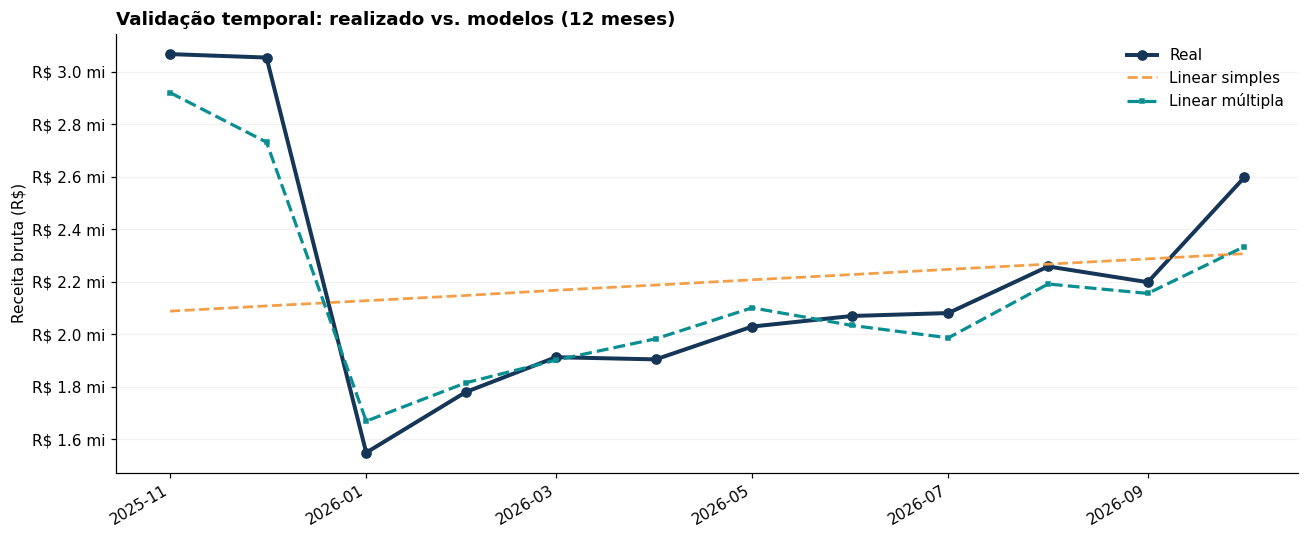

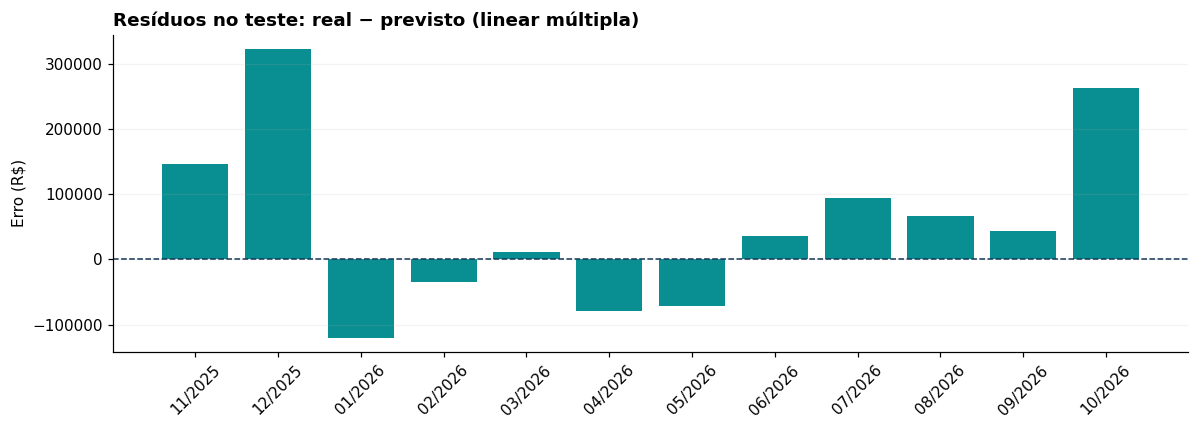

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(teste["mes_referencia"], teste[ALVO], label="Real", color=COR_AZUL, lw=2.6, marker="o")
ax.plot(teste["mes_referencia"], pred_simples, label="Linear simples", color=COR_LARANJA, ls="--", lw=1.8)
ax.plot(teste["mes_referencia"], pred_multipla, label="Linear múltipla", color=COR_TURQUESA, ls="--", lw=2.1, marker="s", markersize=3.2)
ax.set_title("Validação temporal: realizado vs. modelos (12 meses)", loc="left", weight="bold")
ax.set_ylabel("Receita bruta (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(abreviar_milhoes))
ax.grid(axis="y", alpha=.17)
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "03_validacao_temporal.png", dpi=180)
plt.show()

residuos = teste[ALVO].to_numpy() - pred_multipla
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(teste["mes_referencia"].dt.strftime("%m/%Y"), residuos, color=COR_TURQUESA)
ax.axhline(0, ls="--", color=COR_AZUL, lw=1)
ax.set_title("Resíduos no teste: real − previsto (linear múltipla)", loc="left", weight="bold")
ax.set_ylabel("Erro (R$)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=.15)
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "04_residuos_teste.png", dpi=180)
plt.show()

## 5. Projeção para os seis meses seguintes

Reajustamos a regressão múltipla **com todos os meses históricos disponíveis**, depois da avaliação temporal. Para o futuro (novembro/2026–abril/2027), o **plano de mídia-base** representa **+8% de investimento** em relação ao mesmo mês do ano anterior. Testamos orçamento 10% abaixo e 10% acima desse plano.

As diferenças entre cenários são **associações estimadas pelo modelo**, não efeitos causais garantidos do investimento. Não há intervalos de confiança calibrados neste exercício.

Orçamento-base = mês correspondente do ano anterior × 1,08.


,mes_referencia,investimento_base_brl,projecao_conservador_brl,projecao_base_brl,projecao_otimista_brl
0,2026-11-01,112160.99,3133477.76,3200967.69,3268457.62
1,2026-12-01,108337.13,2979777.43,3044966.45,3110155.47
2,2027-01-01,78752.28,1827024.74,1874411.86,1921798.98
3,2027-02-01,92562.43,1987697.70,2043394.70,2099091.71
4,2027-03-01,87184.20,2085412.19,2137872.99,2190333.79
5,2027-04-01,96148.85,2147727.81,2205582.86,2263437.90


Projeção base acumulada (6 meses): R$ 14,507,196.55


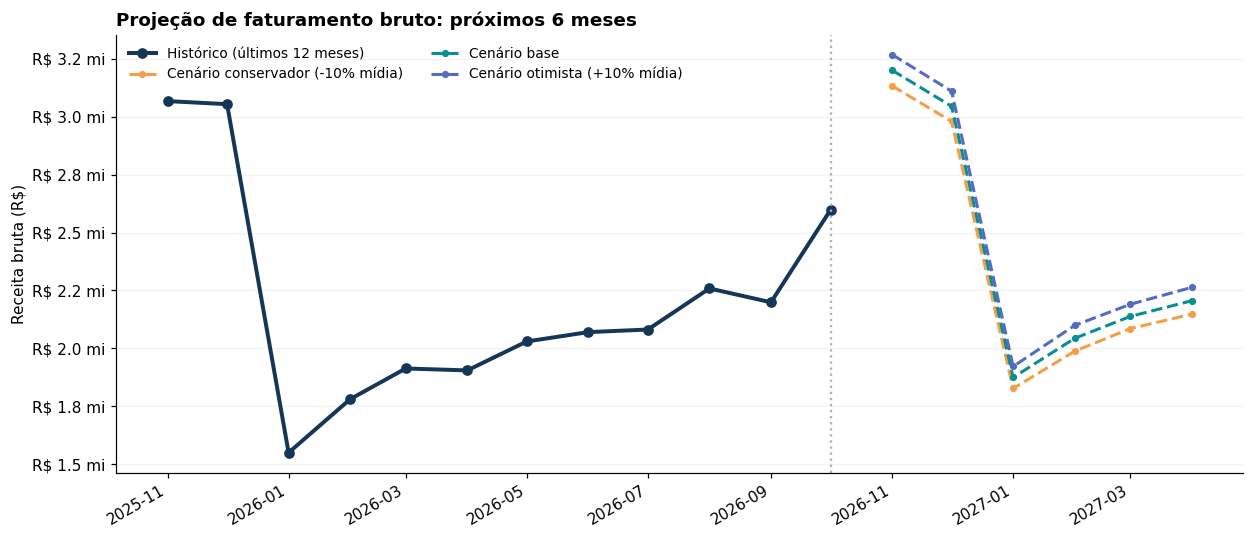

In [6]:
modelo_final = Pipeline(steps=[
    ("tratamento", ColumnTransformer(transformers=[
        ("mes_sazonal", OneHotEncoder(drop="first", handle_unknown="ignore"), ["mes"])
    ], remainder="passthrough")),
    ("modelo", LinearRegression())
])
modelo_final.fit(mensal[COLUNAS], mensal[ALVO])

meses_futuros = pd.date_range(mensal["mes_referencia"].max() + pd.offsets.MonthBegin(1),
                              periods=6, freq="MS")
orcamento_por_mes = mensal.set_index("mes_referencia")["investimento_marketing_brl"]
futuro = pd.DataFrame({
    "mes_referencia": meses_futuros,
    "mes": meses_futuros.month,
    "indice_tempo": np.arange(len(mensal), len(mensal) + len(meses_futuros)),
    "investimento_base_brl": [float(orcamento_por_mes.loc[d - pd.DateOffset(years=1)] * 1.08)
                                for d in meses_futuros],
})

for cenario, fator in [("conservador", 0.9), ("base", 1.0), ("otimista", 1.1)]:
    entradas = futuro[["mes", "indice_tempo"]].copy()
    entradas["investimento_marketing_brl"] = futuro["investimento_base_brl"] * fator
    futuro[f"projecao_{cenario}_brl"] = modelo_final.predict(entradas[COLUNAS]).round(2)

assert (futuro[["projecao_conservador_brl", "projecao_base_brl", "projecao_otimista_brl"]] > 0).all().all()
projecao_export = futuro[["mes_referencia", "investimento_base_brl",
                         "projecao_conservador_brl", "projecao_base_brl", "projecao_otimista_brl"]].copy()
projecao_export["mes_referencia"] = projecao_export["mes_referencia"].dt.strftime("%Y-%m-%d")
projecao_export.to_csv(PASTA_RESULTADOS / "projecao_6_meses.csv", index=False, encoding="utf-8-sig")
print("Orçamento-base = mês correspondente do ano anterior × 1,08.")
display(projecao_export.round(2))
print(f"Projeção base acumulada (6 meses): R$ {futuro['projecao_base_brl'].sum():,.2f}")

fig, ax = plt.subplots(figsize=(11.5, 5))
hist = mensal.tail(12)
ax.plot(hist["mes_referencia"], hist[ALVO], color=COR_AZUL, lw=2.6, marker="o", label="Histórico (últimos 12 meses)")
for coluna, cor, label in [
    ("projecao_conservador_brl", COR_LARANJA, "Cenário conservador (-10% mídia)"),
    ("projecao_base_brl", COR_TURQUESA, "Cenário base"),
    ("projecao_otimista_brl", "#556BC1", "Cenário otimista (+10% mídia)")
]:
    ax.plot(futuro["mes_referencia"], futuro[coluna], label=label, color=cor, ls="--", lw=2, marker="o", markersize=3.7)
ax.axvline(hist["mes_referencia"].max(), color="#A8B3BD", ls=":", lw=1.5)
ax.set_title("Projeção de faturamento bruto: próximos 6 meses", loc="left", weight="bold")
ax.set_ylabel("Receita bruta (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(abreviar_milhoes))
ax.grid(axis="y", alpha=.15)
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "05_projecao_cenarios.png", dpi=180)
plt.show()

## 6. Leitura executiva e limitações

- **Lógica de negócio:** sazonalidade de novembro/dezembro e orçamento de mídia são incorporados ao modelo; sessões/pedidos/ticket entram na EDA, não como explicativas futuras.
- **Seleção de modelo:** avaliar MAPE, MAE, RMSE e R², sempre no bloco temporal reservado. Verificar desempenho contra baseline sazonal e regressão simples.
- **Interpretação:** coeficientes são associações observadas na base sintética e **não demonstram causalidade**. Projeções dependem das premissas sobre o investimento futuro.
- **Limites:** base fictícia, poucos ciclos anuais, mudanças de preço e mix de categorias não previstas separadamente; nenhuma garantia de precisão fora do período de validação.
- **Próximo passo:** simular cenários comerciais (margem, descontos, logística), rolling-origin cross-validation e modelos alternativos (regularização Ridge, SARIMAX ou XGBoost).

In [7]:
vencedor = avaliacao.iloc[0]
melhor_mult = avaliacao.loc[avaliacao["modelo"] == "Regressao linear multipla"].iloc[0]
print("RESUMO EXECUTIVO — PROJETO SINTÉTICO")
print(f"Menor MAPE do teste: {vencedor['modelo']} ({vencedor['MAPE (%)']:.2f}%)")
print(f"Regressão múltipla: MAPE {melhor_mult['MAPE (%)']:.2f}% | R² {melhor_mult['R2']:.3f}")
print(f"Projeção-base para 6 meses: R$ {futuro['projecao_base_brl'].sum():,.2f}")
print("Todas as projeções são condicionais a orçamentos simulados, sem interpretação causal.")

RESUMO EXECUTIVO — PROJETO SINTÉTICO
Menor MAPE do teste: Regressao linear multipla (4.55%)
Regressão múltipla: MAPE 4.55% | R² 0.904
Projeção-base para 6 meses: R$ 14,507,196.55
Todas as projeções são condicionais a orçamentos simulados, sem interpretação causal.
